,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers



 (2443651, 9)

 Frequency table by category:


,category,absolute_frequency,relative_frequency
0,Sports & Outdoors,836265,34.22
1,Beauty,19312,0.79
2,"Handmade Clothing, Shoes & Accessories",19229,0.79
3,Bath & Body,19092,0.78
4,Birthday Gifts,18978,0.78
...,...,...,...
291,Alexa Built-In Devices,107,0.00
292,Motorbike Chassis,107,0.00
293,Plugs,107,0.00
294,Smart Home Security & Lighting,104,0.00



 Top 5 most listed product categories:


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

/var/folders/5l/d76xm4td69x828mtm3bkbxhh0000gn/T/ipykernel_31159/3152812568.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df[df['category'].isin(top_5_categories.index)], x='category', order=top_5_categories.index, palette='Set2')


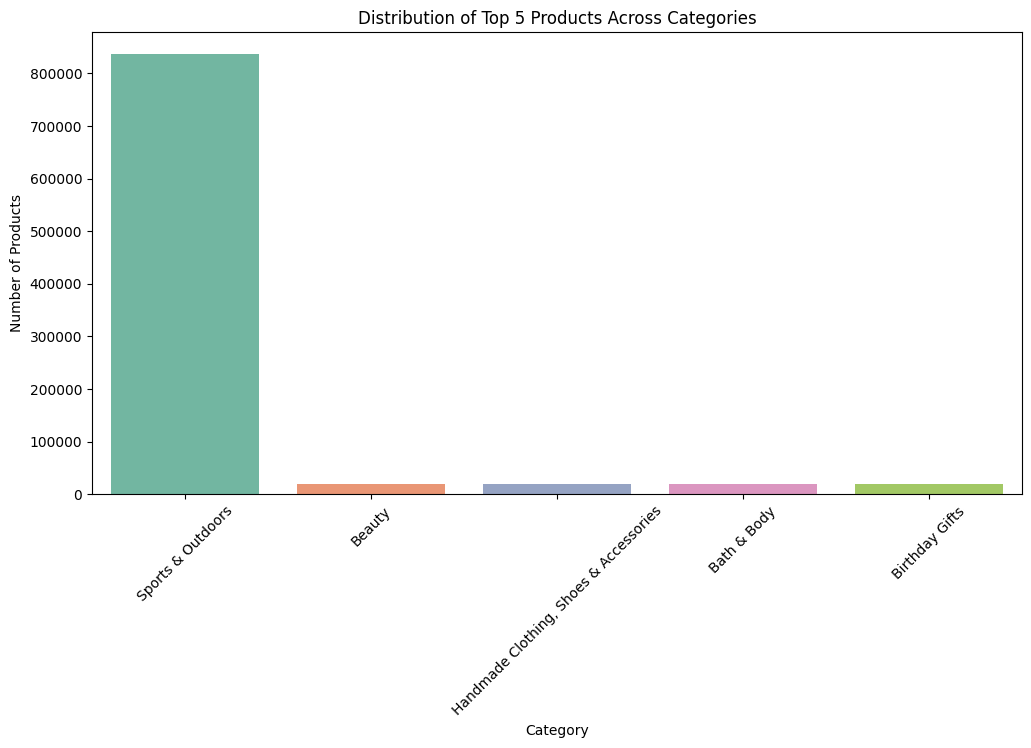

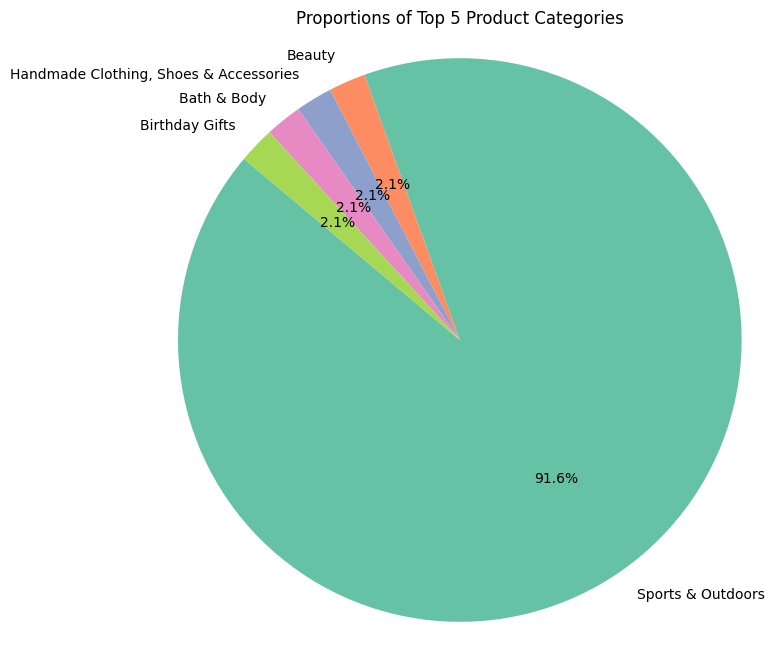


 The pie chart shows that sports and outdoors products dominate the listings.

 Mean Price: 89.24
 Median Price: 19.09
 Mode Price: 9.99

 The average price point of products listed is 89.24, while the most common price point (mode) is 9.99.

 The average price is higher than the mode, indicating that while most products are priced lower, there are some high-priced items that raise the average.

 Price Variance: 119445.49
 Price Standard Deviation: 345.61
 Price Range: 100000.00
 Price Interquartile Range: 36.00

 The high standard deviation and wide range indicate a significant spread in product prices, suggesting a diverse market with both low-cost and high-end products.


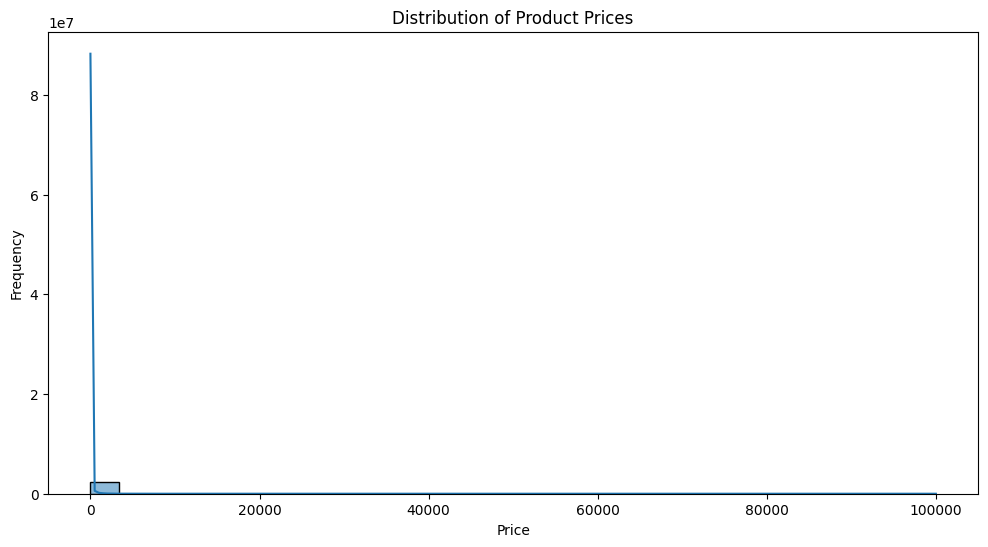


 The histogram is hard to read due to extreme values skewing the distribution and the linear x scale is accentuating this issue.
In order to solve this, we can consider removing the extreme values or applying a logarithmic scale for the x-axis.


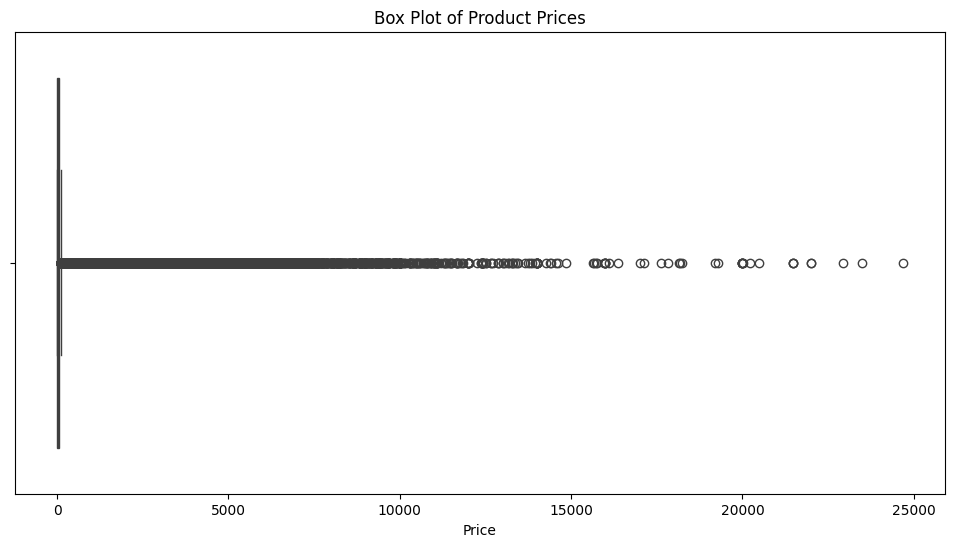


 The box plot reveals several outliers in product pricing, indicating that there are indeed products priced significantly higher than the rest.

 Mean Rating: 2.15
 Median Rating: 0.00
 Mode Rating: 0.00

 Customers generally rate products quite highly, with an average rating of 2.15 and a median rating of 0.00.

 The mode rating of 5.0 indicates that many customers give the highest possible rating, suggesting a trend of positive feedback.

 Rating Variance: 4.82
 Rating Standard Deviation: 2.19
 Rating Interquartile Range: 4.40

 The ratings are quite consistent, as evidenced by the low variance and standard deviation. 
Most customers seem to agree on the quality of the products they purchase.

 Rating Skewness: 0.08
 Rating Kurtosis: -1.93

 The skewness of 0.08 indicates a slight right skew, suggesting that there are more high ratings than low ratings.

 The kurtosis value suggests a distribution that is somewhat peaked, indicating that ratings are concentrated around the mean with

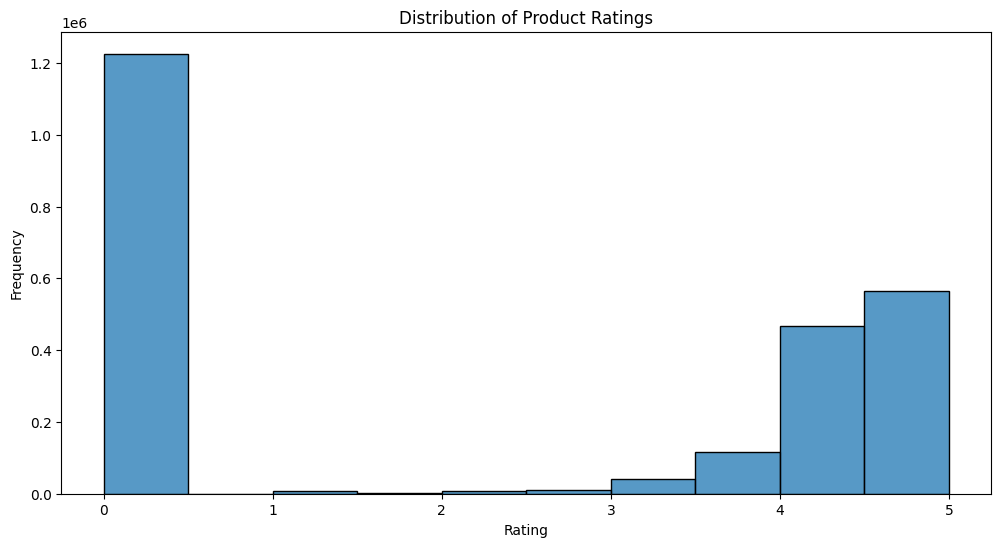


 The histogram shows that a rating of 5.0 is the most common, indicating that many customers are very satisfied with their purchases.


In [17]:
# --------- EDA Lab ----------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

# Quick look at the data
display(df.head())
print("\n", df.shape)

# Part 1: Understanding Product Categories

# 1.1 Frequency table for the product "category"
# Calculation of absolute frequencies
absolute_freq = df['category'].value_counts().reset_index()
absolute_freq.columns = ['category', 'absolute_frequency']

# Calculation of relative frequencies (in %)
relative_freq = (df['category'].value_counts(normalize=True) * 100).reset_index()
relative_freq.columns = ['category', 'relative_frequency']

# Merge the two tables
frequency_table = pd.merge(absolute_freq, relative_freq, on='category')

# Round the relative frequency to 2 decimal places
frequency_table['relative_frequency'] = frequency_table['relative_frequency'].round(2)

# Final result
print("\n Frequency table by category:")
display(frequency_table)

# 1.2 Top 5 most listed product categories
top_5_categories = df['category'].value_counts().head(5)
print("\n Top 5 most listed product categories:")
display(top_5_categories)

# 2.1 Distribution of top 5 products across different categories
plt.figure(figsize=(12, 6))
sns.countplot(data=df[df['category'].isin(top_5_categories.index)], x='category', order=top_5_categories.index, palette='Set2')
plt.title('Distribution of Top 5 Products Across Categories')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.show()

# 2.2 Proportions of product categories
plt.figure(figsize=(8, 8))
plt.pie(top_5_categories, labels=top_5_categories.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set2', n_colors=5))
plt.title('Proportions of Top 5 Product Categories')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

# Insights
print("\n The pie chart shows that sports and outdoors products dominate the listings.")


# Part 2: Delving into Product Pricing
# 1.1 Calculation of the mean, median, and mode for the price of products
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]
print(f"\n Mean Price: {mean_price:.2f}")
print(f" Median Price: {median_price:.2f}")
print(f" Mode Price: {mode_price:.2f}")

# 1.2 Insights
print(f"\n The average price point of products listed is {mean_price:.2f}, while the most common price point (mode) is {mode_price:.2f}.")
print("\n The average price is higher than the mode, indicating that while most products are priced lower, there are some high-priced items that raise the average.")

# 2.1 Calculation of the variance, standard deviation, range, and interquartile range for product "price"
price_variance = df['price'].var()
price_std_dev = df['price'].std()
price_range = df['price'].max() - df['price'].min()
price_iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"\n Price Variance: {price_variance:.2f}")
print(f" Price Standard Deviation: {price_std_dev:.2f}")
print(f" Price Range: {price_range:.2f}")
print(f" Price Interquartile Range: {price_iqr:.2f}")

# 2.2 Insights
print("\n The high standard deviation and wide range indicate a significant spread in product prices, suggesting a diverse market with both low-cost and high-end products.")

# 3.1 Distribution of product prices
plt.figure(figsize=(12, 6))
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()
print("""\n The histogram is hard to read due to extreme values skewing the distribution and the linear x scale is accentuating this issue.
In order to solve this, we can consider removing the extreme values or applying a logarithmic scale for the x-axis.""")

# 3.2 Spread and potential outliers in product pricing with x label max at 35000
plt.figure(figsize=(12, 6))
sns.boxplot(x='price', data=df[df['price'] < 35000])
plt.title('Box Plot of Product Prices')
plt.xlabel('Price')
plt.show()
print("\n The box plot reveals several outliers in product pricing, indicating that there are indeed products priced significantly higher than the rest.")

# Part 3: Unpacking Product Ratings
# 1.1 Calculation of the mean, median, and mode for the rating of products
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]
print(f"\n Mean Rating: {mean_rating:.2f}")
print(f" Median Rating: {median_rating:.2f}")
print(f" Mode Rating: {mode_rating:.2f}")

# 1.2 Insights
print(f"\n Customers generally rate products quite highly, with an average rating of {mean_rating:.2f} and a median rating of {median_rating:.2f}.")
print("\n The mode rating of 5.0 indicates that many customers give the highest possible rating, suggesting a trend of positive feedback.")

# 2.1 Calculation of the variance, standard deviation, and interquartile range for product rating
rating_variance = df['stars'].var()
rating_std_dev = df['stars'].std()
rating_iqr = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print(f"\n Rating Variance: {rating_variance:.2f}")
print(f" Rating Standard Deviation: {rating_std_dev:.2f}")
print(f" Rating Interquartile Range: {rating_iqr:.2f}")

# 2.2 Insights
print("""\n The ratings are quite consistent, as evidenced by the low variance and standard deviation. 
Most customers seem to agree on the quality of the products they purchase.""")

# 3.1 Calculate the skewness and kurtosis for the rating column
rating_skewness = df['stars'].skew()
rating_kurtosis = df['stars'].kurtosis()

print(f"\n Rating Skewness: {rating_skewness:.2f}")
print(f" Rating Kurtosis: {rating_kurtosis:.2f}")

# 3.2 Insights
print(f"\n The skewness of {rating_skewness:.2f} indicates a slight right skew, suggesting that there are more high ratings than low ratings.")
print("\n The kurtosis value suggests a distribution that is somewhat peaked, indicating that ratings are concentrated around the mean with fewer extreme values.")

# 4. Distribution of product ratings
plt.figure(figsize=(12, 6))
sns.histplot(df['stars'], bins=10, kde=False)
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

# Insights
print("\n The histogram shows that a rating of 5.0 is the most common, indicating that many customers are very satisfied with their purchases.")
